Notebook personal — objetivo 3 v2, fase 4
Modo predeterminado: verificar predicciones guardadas, sin entrenar.
Protocolo 2.0.2 y 100 configuraciones congeladas, semilla 20261010.
Requiere repositorio completo y entorno exacto fase2/requirements.lock.txt:
Python 3.12.14, sklearn 1.9.1. No instala dependencias ni descarga datos.
Abrir desde el repositorio o fase4/notebooks; ejecutar las celdas en orden.
Entradas: panel fase1, configuración fase2 y artefactos guardados fase3.
Salidas de esta verificación: fase4/resultados/notebook_verificacion/.
Los resultados son ecológicos contemporáneos; no efectos causales ni pronósticos
disponibles antes de publicar el IPM. 2025 es exploratorio, no reserva inédita.

In [1]:
import sys
sys.dont_write_bytecode = True
from pathlib import Path
inicio = Path.cwd().resolve()
ROOT = next((p for p in [inicio, *inicio.parents] if (p / 'experimentos_objetivo3_v2/fase4/fuentes/revision.py').is_file()), None)
assert ROOT is not None, 'Ejecutar desde el repositorio o sus subcarpetas'
sys.path.insert(0, str(ROOT / 'experimentos_objetivo3_v2/fase4/fuentes'))
from revision import integridad, revisar, F4, guardar
from presentar import presentar
MODO = 'verificar'  # Cambiar voluntariamente a 'reejecutar' para un piloto NUEVO completo.
assert MODO in ('verificar', 'reejecutar')
verificacion_entorno = integridad()
print('Entorno y huellas aprobados:', verificacion_entorno['python'])
print('Semilla: 20261010; configuración: 2.0.2; 100 candidatos')

Entorno y huellas aprobados: 3.12.14
Semilla: 20261010; configuración: 2.0.2; 100 candidatos


In [2]:
SALIDA = F4 / 'resultados/notebook_verificacion'
metricas, comparaciones, pares, controles = revisar(out=SALIDA)
guardar(SALIDA / 'integridad_consulta.json', verificacion_entorno)
print('Revisión ejecutada sobre artefactos guardados; ajustes nuevos:', controles['ajustes_nuevos_revision'])
print('Condición exacta de entrega:', controles['condicion'])
print(metricas[(metricas.periodo == '2021-2025') & (metricas.ambito == 'conjunto')].to_string(index=False))

Revisión ejecutada sobre artefactos guardados; ajustes nuevos: 0
Condición exacta de entrega: {'entregar': True, 'mejora': 18.392545281085766}
  periodo       procedimiento   ambito grupo   n       mae      rmse     sesgo        r2
2021-2025               media conjunto todos 165 14.642483 17.555927 -2.808165 -0.020533
2021-2025        ols_ambas_00 conjunto todos 165  8.097991 10.138072 -1.811655  0.659678
2021-2025          ols_ipm_00 conjunto todos 165  9.493907 12.251516  1.121005  0.502997
2021-2025        ols_tasas_00 conjunto todos 165  7.361572  8.975052 -2.413730  0.733281
2021-2025 procedimiento_ambas conjunto todos 165  4.821934  6.122266 -0.758414  0.875891
2021-2025   procedimiento_ipm conjunto todos 165  9.304228 11.799012  2.251463  0.539032
2021-2025 procedimiento_tasas conjunto todos 165  4.939188  6.201589 -0.966952  0.872654
2021-2025    procedimiento_v2 conjunto todos 165  4.879557  6.194961 -0.975864  0.872926
2021-2025       referencia_v1 conjunto todos 165  5.9793

2021–2024 separado y aporte de 2025
La condición se calcula sobre las 165 filas de 2021–2025, sin sustituir el
procedimiento por la especificación que parezca mejor en los errores externos.
R² territorial usa cinco observados; puede ser negativo con baja variación.

In [3]:
print(metricas[(metricas.ambito == 'conjunto') & metricas.procedimiento.isin(['procedimiento_v2', 'referencia_v1'])].to_string(index=False))
deterioros = comparaciones[(comparaciones.periodo == '2021-2025') & (comparaciones.procedimiento == 'procedimiento_v2') & (comparaciones.ambito != 'conjunto')]
print(deterioros[['ambito', 'grupo', 'delta_mae', 'delta_rmse', 'deteriora_mae']].to_string(index=False))
print('Diferencias emparejadas, primeras filas:')
print(pares[['codigo_departamento', 'anio', 'delta_error_firmado', 'delta_error_absoluto', 'delta_error_cuadratico']].head().to_string(index=False))

  periodo    procedimiento   ambito grupo   n      mae     rmse     sesgo       r2
2021-2025 procedimiento_v2 conjunto todos 165 4.879557 6.194961 -0.975864 0.872926
2021-2025    referencia_v1 conjunto todos 165 5.979303 7.312387 -0.668285 0.822949
2021-2024 procedimiento_v2 conjunto todos 132 4.845373 6.110624 -0.397297 0.871578
2021-2024    referencia_v1 conjunto todos 132 5.868852 7.181023 -0.196980 0.822645
     2025 procedimiento_v2 conjunto todos  33 5.016294 6.521411 -3.290132 0.864341
     2025    referencia_v1 conjunto todos  33 6.421109 7.815796 -2.553505 0.805144
     ambito grupo  delta_mae  delta_rmse  deteriora_mae
      anual  2021  -0.148591   -0.000554          False
      anual  2022  -1.675486   -1.731409          False
      anual  2023  -1.287644   -1.368083          False
      anual  2024  -0.982194   -1.369427          False
      anual  2025  -1.404815   -1.294385          False
territorial    05   0.827572    1.361457           True
territorial    08  -3.19632

Diferencias: e = predicción − observado. Error firmado v2−v1 indica dirección,
no mejora: positivo puede reducir una subestimación. Error absoluto positivo
indica deterioro de ese par; error cuadrático positivo también, en puntos².
CSV completo: 165 pares. No se presupone independencia temporal o territorial
ni se aplica una prueba de significancia para justificar el umbral práctico.

Gráficos recalculados: mae_anual.png, delta_mae_territorial.png, diferencias_emparejadas.png


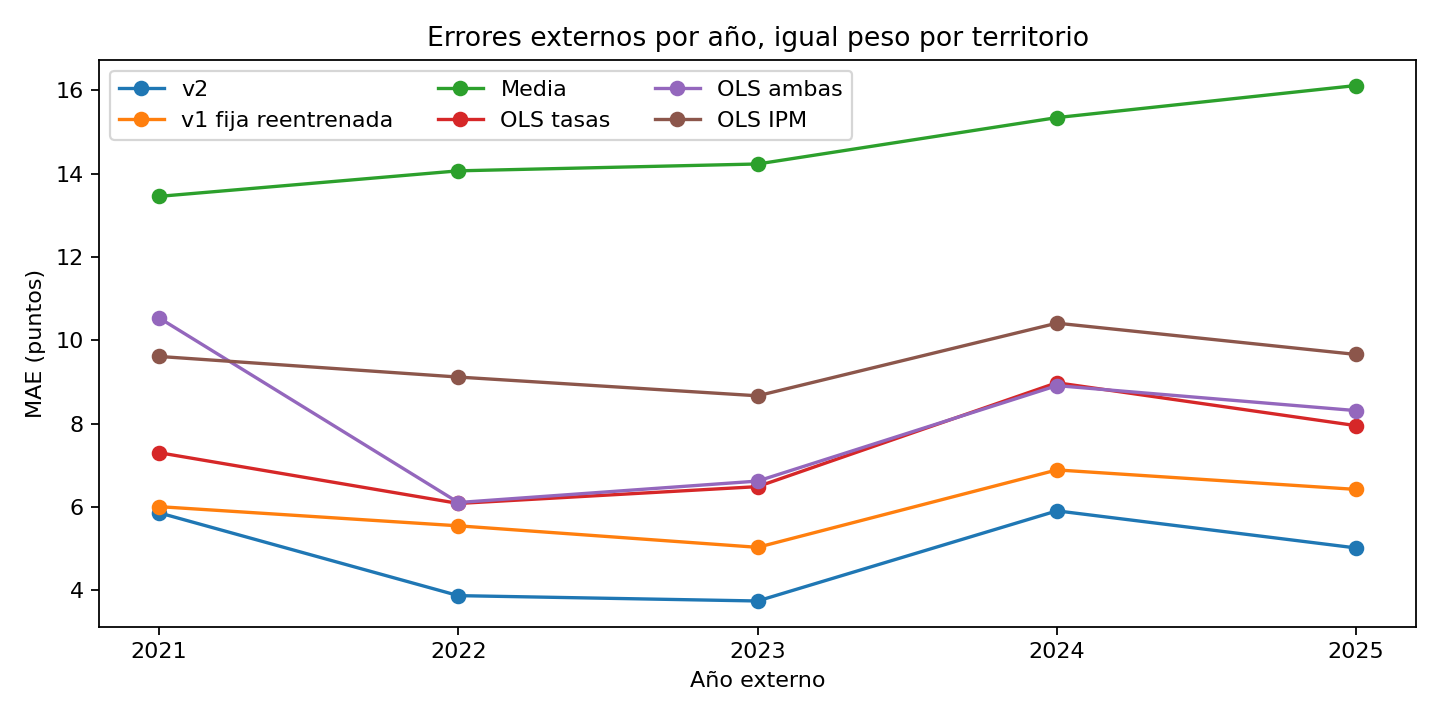

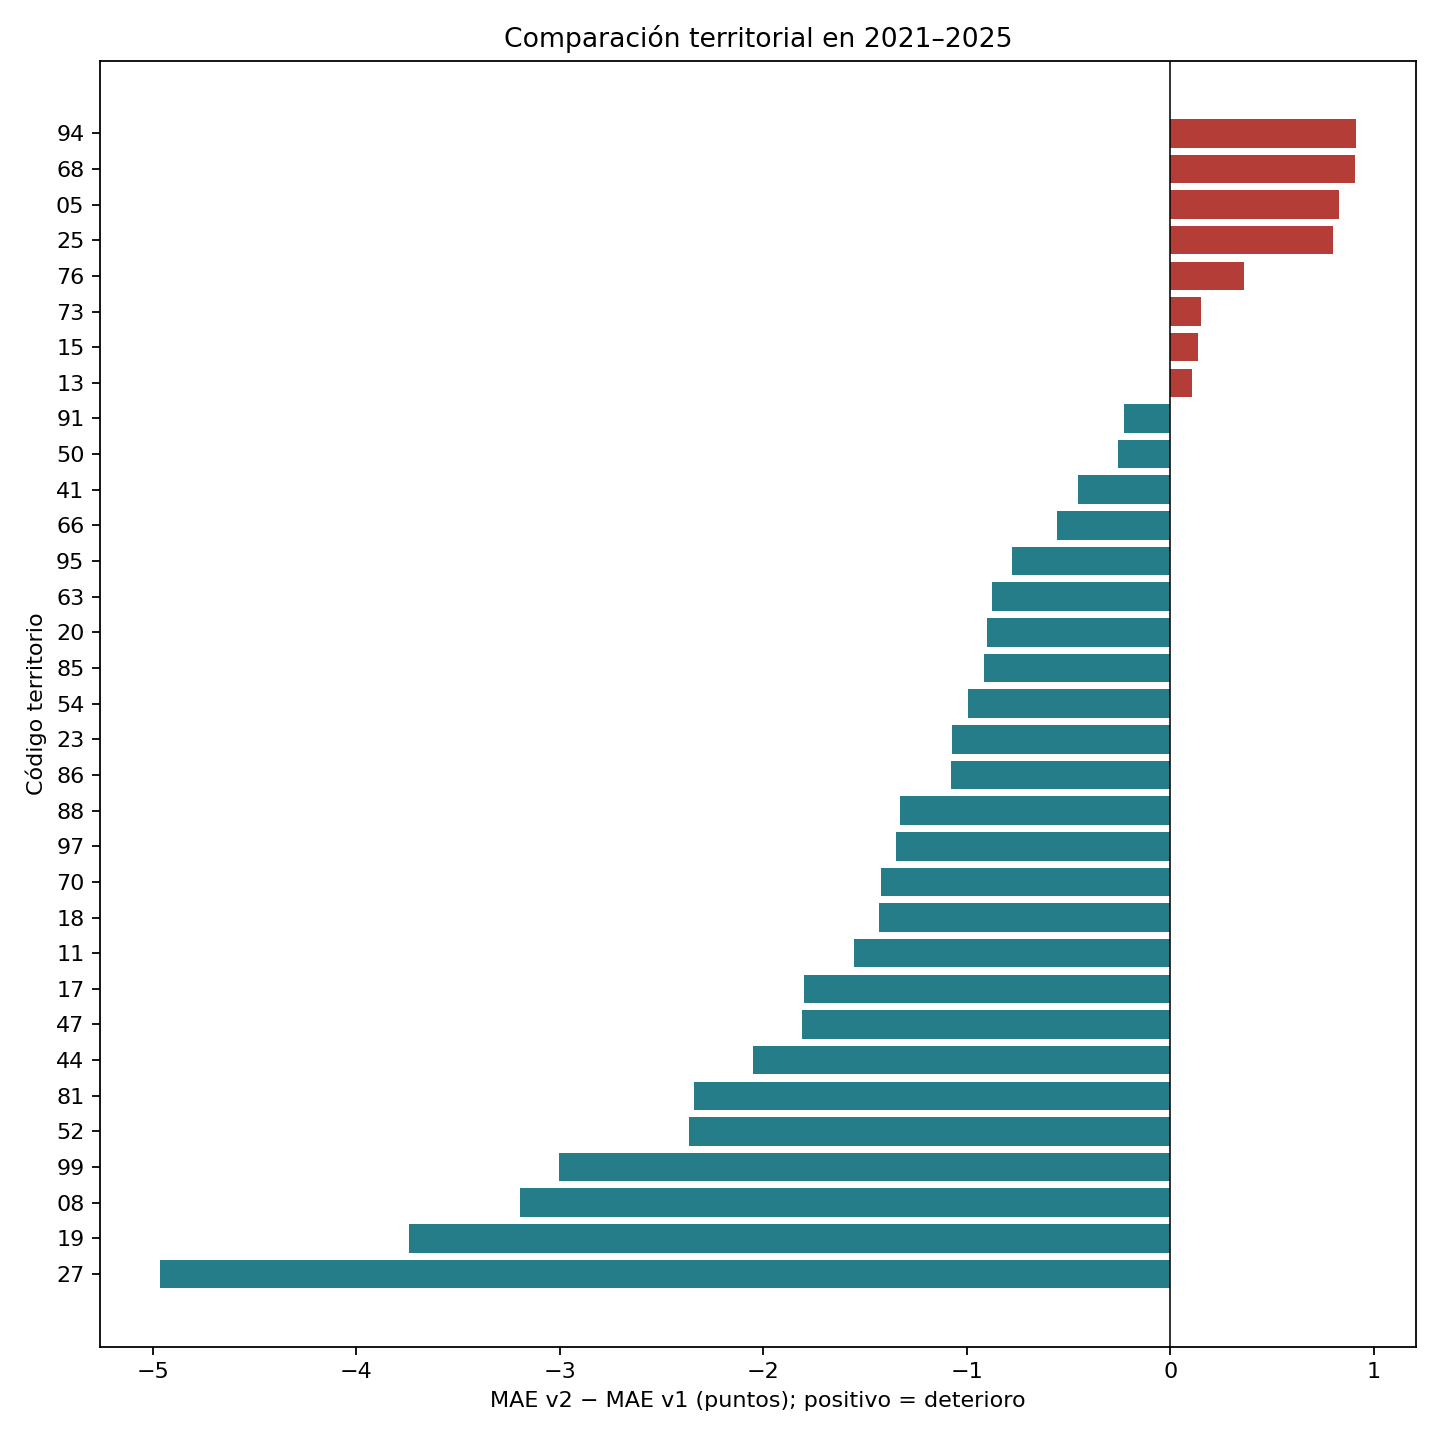

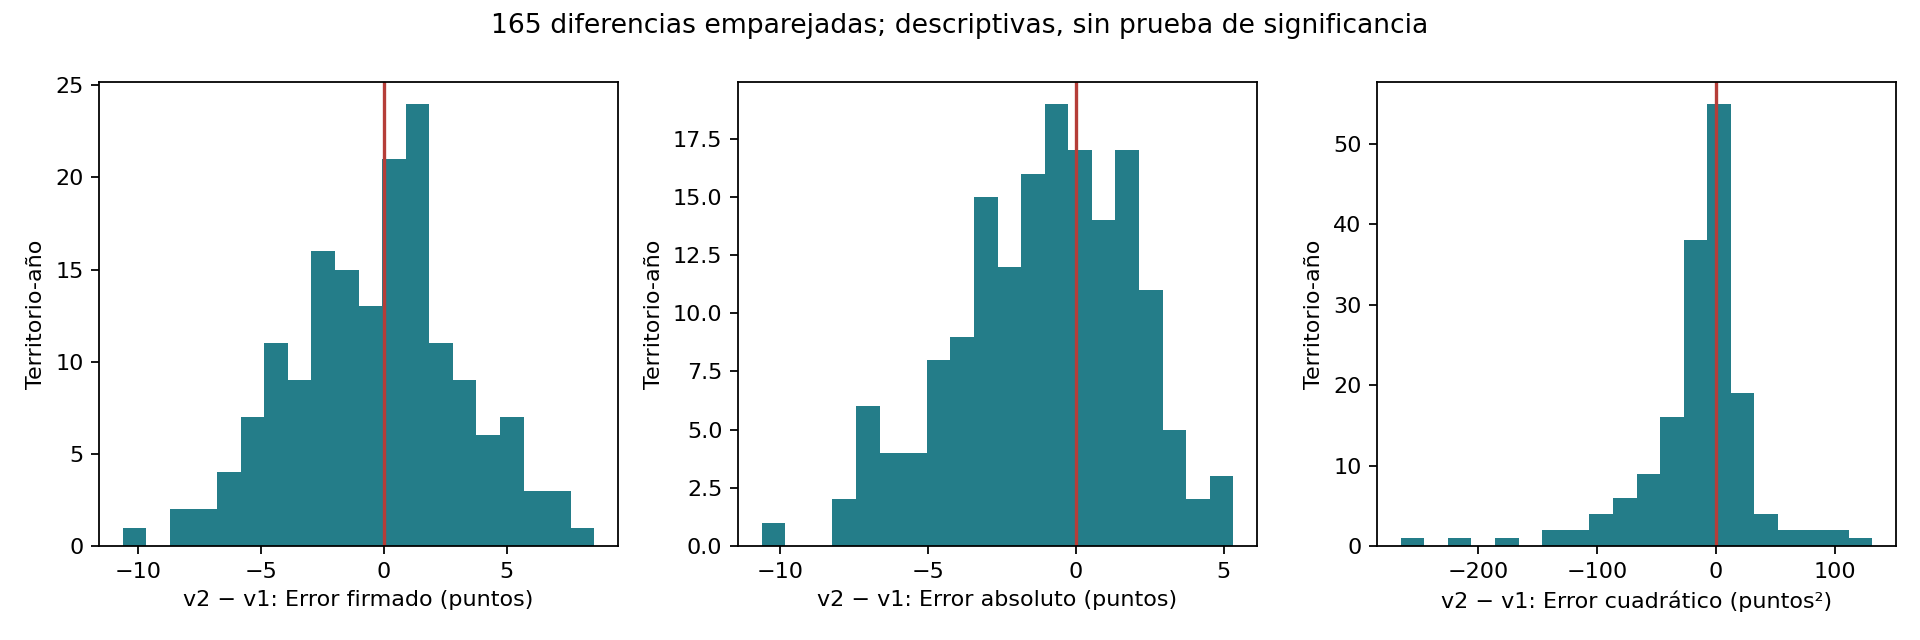

In [4]:
GRAPH_PATHS = presentar(metricas, comparaciones, pares, SALIDA)
print('Gráficos recalculados:', ', '.join(p.name for p in GRAPH_PATHS))

Reejecución voluntaria completa
Cambiar MODO a 'reejecutar' y ejecutar la siguiente celda inicia un piloto nuevo,
con presupuesto máximo de 7200 segundos para TODO el procedimiento, referencias
y repeticiones incluidas. Tiempo histórico observado: 1540.91 segundos (~25.7 min),
sin garantía de duración en otro equipo. Revisión/gráficos quedan fuera del tiempo
de ajustes. Un subproceso ejecuta el motor compartido con un hilo y semilla fija.
Guarda configuración referenciada, ledger propio y controles en una carpeta nueva
fase4/reproducciones/piloto_FECHA/. Nunca reutiliza modelos ni saldo de fase3.
No borrar ni reiniciar el ledger ante una interrupción. Estado incompleto se conserva;
no afirmar reproducción exitosa si falla o agota presupuesto. Esta celda no fue
ejecutada con entrenamiento en la entrega: solo se verificó su rama predeterminada.

In [5]:
if MODO == 'reejecutar':
    import subprocess
    subprocess.run([sys.executable, str(F4 / 'fuentes/reejecutar.py')], cwd=ROOT, check=True)
else:
    print('Modo verificar: no se inició reentrenamiento. La reproducción completa es voluntaria.')

Modo verificar: no se inició reentrenamiento. La reproducción completa es voluntaria.


Límites conservados
Población de casos completos, geografía del colegio, peso igual territorio-año,
IPM y Saber de poblaciones distintas, comparabilidad IPM, dependencia y pocos años.
Guainía: 238 completos frente a 404 con global; diferencia descriptiva 21.012106
puntos (fase1/resultados/diagnostico_medias_disponibles.csv). No identifica causa.
Fuentes locales sin autenticación independiente. 2020 excluido definitivamente.
E3-01 conserva regex temporal completa; E3-02 corrige máximo descriptivo a 1555
sin cambiar 100 candidatos ni 7200 segundos. No hay ajuste final ni simulación.